### Intro Node

In [26]:
from typing import TypedDict, Literal, Annotated
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from IPython.display import display, Image

In [5]:
# 1. State
class SimpleState(TypedDict):
    name: str # Input
    greeting: str # Output

In [6]:
# 2. Node
def greet_node(state: SimpleState):
    print("greet_node called with state:", state)
    return {"greeting": f"Hello, {state['name']}!"}

def uppercase_node(state: SimpleState):
    print("uppercase_node called with state:", state)
    return {"greeting": state["greeting"].upper()}

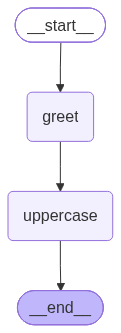

In [8]:
# 3. Graph
graph_builder = StateGraph(SimpleState)
# 3.1 Add nodes
graph_builder.add_node("greet", greet_node)
graph_builder.add_node("uppercase", uppercase_node)
# 3.2 Add edges
graph_builder.add_edge(START, "greet")
graph_builder.add_edge("greet", "uppercase")
graph_builder.add_edge("uppercase", END)
# 3.3. Compile the graph
graph = graph_builder.compile()


display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
# Test graph, graph input / output all state

result = graph.invoke({"name": "Alice"})

print(result)

greet_node called with state: {'name': 'Alice'}
uppercase_node called with state: {'name': 'Alice', 'greeting': 'Hello, Alice!'}
{'name': 'Alice', 'greeting': 'HELLO, ALICE!'}


## Customized Reducer - change behavior of Node updating State

In [ ]:
from typing import Annotated, TypedDict

from langgraph.constants import START, END
from langgraph.graph import StateGraph


def add_reducer(old_value, new_value):
    return old_value + new_value

# =================1. 定义State数据结构和Reducer=================
class CustomReducerState(TypedDict):
    count: int                       # 这个字段没有定义Reducer，也就是默认会覆盖旧值
    nodes: Annotated[list[str], add_reducer] # 这里使用add作为Reducer，也就是会拼接结果

# =================2. Node: 定义处理逻辑=================
def node_1(state: CustomReducerState):
    print(f'node_1 is receiving count: {state['count']}')
    return {'count': 1, 'nodes': ['node_1']} # 直接修改nodes值，不用自己拼接

def node_2(state: CustomReducerState):
    print(f'node_2 is receiving count: {state['count']}')
    return {'count': 2, 'nodes': ['node_2']} # 直接修改nodes值，不用自己拼接

# ===================3. 创建Graph===================
graph_builder = StateGraph(CustomReducerState)      #  in LangGraph, you always define the state schema as a class and pass it to the graph - the graph needs that class reference to read the reducers at runtime.
graph_builder.add_node('node_1', node_1)            # 3.2.注册Node
graph_builder.add_node('node_2', node_2)
                                                    # 3.3.注册Edge，定义Node执行顺序
graph_builder.add_edge(START, 'node_1')                 # START -> greet
graph_builder.add_edge('node_1', 'node_2')              # greet -> uppercase
graph_builder.add_edge('node_2', END)                   # uppercase -> END

graph = graph_builder.compile()                     # 3.4.编译成可执行图

# =================4.调用Graph，传入默认State值=================
result = graph.invoke({'count': 0, 'nodes':[]})
print(result)

node_1 is receiving count: 0
node_2 is receiving count: 1
{'count': 2, 'nodes': ['node_1', 'node_2']}


## Parallel Graph

In [25]:
from operator import add
from typing import Annotated, TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# =================1. 定义State数据结构和Reducer=================
class ParallelState(TypedDict):
    nodes: Annotated[list[str], add]

# =================2. Node: 定义处理逻辑=================
def node_a(state: ParallelState):
    print(f"node_a is running, nodes: {state['nodes']}")
    return {"nodes": ["a"]}


def node_b(state: ParallelState):
    print(f"node_b is running, nodes: {state['nodes']}")
    return {"nodes": ["b"]}

def node_c(state: ParallelState):
    print(f"node_c is running, nodes: {state['nodes']}")
    return {"nodes": ["c"]}

def node_d(state: ParallelState):
    print(f"node_d is running, nodes: {state['nodes']}")
    return {"nodes": ["d"]}

# ===================3. 创建Graph===================
builder = StateGraph(ParallelState)
builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)
builder.add_node("d", node_d)
builder.add_edge(START, "a")         # start -> a
builder.add_edge("a", "b")           # a -> b
builder.add_edge("a", "c")           # a -> c
builder.add_edge("b", "d")           # b -> d
builder.add_edge("c", "d")           # c -> d
builder.add_edge("d", END)           # d -> end
parallel_graph = builder.compile()

# =================4.调用Graph，传入默认State值=================
result = parallel_graph.invoke({})
print(result)

node_a is running, nodes: []
node_b is running, nodes: ['a']
node_c is running, nodes: ['a']
node_d is running, nodes: ['a', 'b', 'c']
{'nodes': ['a', 'b', 'c', 'd']}


## Conditional Edge

In [30]:
class ScoreState(TypedDict):
    score: int
    result: str

def scorer(state: ScoreState):
    score = int(input("请输入分数:"))
    print(score)
    return {"score": score}  # 模拟评分


def pass_node(state: ScoreState):
    return {"result": "通过！"}


def fail_node(state: ScoreState):
    return {"result": "不通过！"}


def router(state: ScoreState) -> Literal["pass", "fail"]:
    if state["score"] < 60:
        return "fail"
    else:
        return "pass"



builder = StateGraph(ScoreState) 
builder.add_node("scorer", scorer)                  # 打分节点
builder.add_node("pass", pass_node)                 # 失败节点
builder.add_node("fail", fail_node)                 # 成功节点

builder.add_edge(START, "scorer")                   # start -> scorer
builder.add_conditional_edges("scorer", router)     # scorer -> router （条件边）
builder.add_edge("pass", END)                       # pass -> end
builder.add_edge("fail", END)                       # fail -> end
condition_graph=builder.compile()


result = condition_graph.invoke({})
print(result)


150
{'score': 150, 'result': '通过！'}


In [32]:
# Edge + Command: node to conditionalk 
from langgraph.types import Command
class ScoreState(TypedDict):
    score: int
    result: str

def scorer(state: ScoreState)->Command[Literal["pass", "fail"]]:
    score = int(input("请输入分数:"))
    print(score)
    goto = "pass"
    if score < 60:
        goto = "fail"
    return Command(update={"score": score},goto=goto)  # 模拟评分


def pass_node(state: ScoreState):
    return {"result": "通过！"}


def fail_node(state: ScoreState):
    return {"result": "不通过！"}



builder = StateGraph(ScoreState) 
builder.add_node("scorer", scorer)                  # 打分节点
builder.add_node("pass", pass_node)                 # 失败节点
builder.add_node("fail", fail_node)                 # 成功节点

builder.add_edge(START, "scorer")                   # start -> scorer
builder.add_edge("pass", END)                       # pass -> end
builder.add_edge("fail", END)                       # fail -> end
condition_graph=builder.compile()


result = condition_graph.invoke({})
print(result)


62
{'score': 62, 'result': '通过！'}
